In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Задача 1. Сравнение кредитных выборок

Есть два ряда кредитов, которые были выданы двум разным сегментам пользователей.

Необходимо выяснить, существует ли разница в кредитах, которые выдаются двум сегментам.

**Задача:**

- Построй по отдельности гистограммы для двух сегментов. Отметь на них средние выборочные значения кредитов;

- Проверь, что средние значения кредитов в двух выборках равны с помощью рассчитанного вручную z-критерия;

- Проверь, что средние значения кредитов в двух выборках равны с помощью автоматического расчёта t-критерия;

- Проверь, что средние дисперсии кредитов в двух выборках равны с помощью рассчитанного вручную F-критерия;



In [ ]:
dfb = pd.read_csv('credit_lists.csv')
dfb.head()

,type,amt_credit
0,POS-2,150000
1,POS-2,50000
2,POS-2,75000
3,POS-1,25000
4,POS-1,50000


In [ ]:
pos1 = dfb[dfb['type']=='POS-1']['amt_credit']
pos2 = dfb[dfb['type']=='POS-2']['amt_credit']

In [ ]:
mean_pos1 = pos1.mean()
mean_pos2 = pos2.mean()

var_pos1 = pos1.var()
var_pos2 = pos2.var()

std_pos1 = pos1.std()
std_pos2 = pos2.std()

n_pos1 = pos1.count()
n_pos2 = pos2.count()

print("Средний кредит в 1 сегменте = ", mean_pos1)
print("Средний кредит во 2 сегменте = ", mean_pos2)
print()
print("Кол-во кредитов в группе-1 = ", n_pos1)
print("Кол-во кредитов в группе-2 = ", n_pos2)

Средний кредит в 1 сегменте =  97028.81152460985
Средний кредит во 2 сегменте =  102020.95808383233

Кол-во кредитов в группе-1 =  833
Кол-во кредитов в группе-2 =  668


## Пункт 1. Визуализация


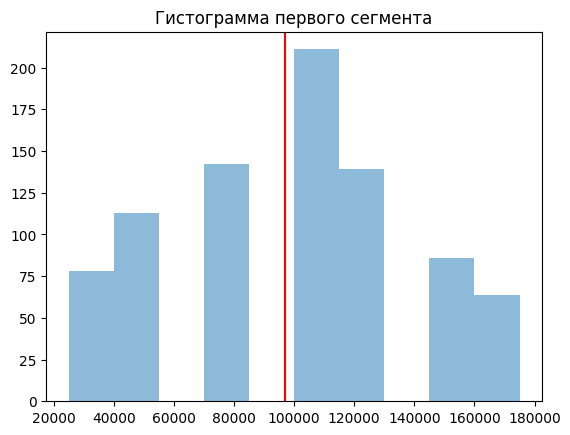

In [ ]:
plt.hist(pos1, alpha=.5)
plt.title("Гистограмма первого сегмента")
plt.axvline(mean_pos1, color='red')
plt.show()

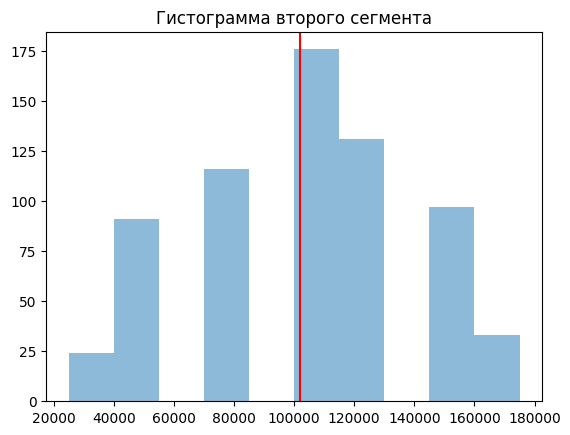

In [ ]:
plt.hist(pos2, alpha=.5)
plt.title("Гистограмма второго сегмента")
plt.axvline(mean_pos2, color='red')
plt.show()

## Пункт 2. Двухвыборочный z-критерий

Рассчитаем двухвыборочный z-критерий

In [ ]:
from scipy.stats import norm

In [ ]:
z_crit = (mean_pos1 - mean_pos2)/(var_pos1 / len(pos1) + var_pos2 /len(pos2))**.5
p_val_z = 2 * norm.sf(abs(z_crit))  # почему не cdf ?

print("Значение стат.критерия z = ", z_crit)
print("p-value z-теста = ", p_val_z)

Значение стат.критерия z =  -2.427850867235507
p-value z-теста =  0.015188587360395413


**Вывод:**

Сегменты отличаются с точки зрения среднего кредита (из расчёта по z-тесту).

## Пункт 3. F-тест

Мы хотим перейти от z-критерия к t-критерию, но помним, что есть два вида t-критерия: Стьюдента и Уэлча. Для выбора необходимо проверить, равны ли в двух выборках дисперсии, для этого воспользуемся F-тестом.

In [ ]:
print("Дисперсия pos1 = ", var_pos1)
print("Дисперсия pos2 = ", var_pos2)

Дисперсия pos1 =  1760241957.3598707
Дисперсия pos2 =  1412701209.275605


Для расчёта F-статистики разделим дисперсию первого сегмента на дисперсию второго. Порядок фиксируем независимо от того, какая дисперсия больше.

Проверяем гипотезы:

$$H_0: \sigma_1^2 = \sigma_2^2, \qquad H_1: \sigma_1^2 \ne \sigma_2^2.$$

Отвергаем $H_0$, если F-статистика меньше нижней критической границы или больше верхней.

In [ ]:
from scipy.stats import f

In [ ]:
alpha = 0.05

# Всегда делим дисперсию первого сегмента на дисперсию второго
F_calc = var_pos1 / var_pos2
df1, df2 = n_pos1 - 1, n_pos2 - 1

# Две критические границы для двусторонней проверки
lower_crit = f.ppf(alpha / 2, df1, df2)
upper_crit = f.ppf(1 - alpha / 2, df1, df2)

# Двустороннее p-value
p_value = 2 * min(
    f.cdf(F_calc, df1, df2),
    f.sf(F_calc, df1, df2)
) # тк не знаем что больше var_pos1 или var_pos2

In [ ]:
print(f"F = {F_calc:.4f}")
print(f"Нижняя критическая граница = {lower_crit:.4f}")
print(f"Верхняя критическая граница = {upper_crit:.4f}")
print(f"p-value = {p_value:.4g}")

if F_calc < lower_crit or F_calc > upper_crit:
    print("Отвергаем H0: дисперсии статистически значимо различаются.")
else:
    print("Не отвергаем H0: статистически значимое различие дисперсий не выявлено.")

F = 1.2460
Нижняя критическая граница = 0.8662
Верхняя критическая граница = 1.1558
p-value = 0.002941
Отвергаем H0: дисперсии статистически значимо различаются.


**Вывод:**

Сегменты отличаются с точки зрения дисперсии (из расчёта по F-тесту).

Таким образом, для следующего пункта выбираем критерий Уэлча, а не критерий Стьюдента.

## Пункт 4. t-тест

Выбираем тест Уэлча для разных дисперсий.

In [ ]:
from scipy.stats import ttest_ind

s, p = ttest_ind(pos1, pos2, equal_var=False)

print("Значение стат.критерия t = ", s)
print("p-value t-теста = ", p)

Значение стат.критерия t =  -2.4278508672355095
p-value t-теста =  0.015307100465100964


**Вывод:**

Сегменты отличаются с точки зрения среднего кредита (из расчёта по t-тесту).

**P.S.**

Если бы мы предположили, что дисперсии равны, то на сколько отличалось бы p-value теста?

In [ ]:
s, p = ttest_ind(pos1, pos2)

print("Значение стат.критерия t = ", s)
print("p-value t-теста = ", p)

Значение стат.критерия t =  -2.3987730331797206
p-value t-теста =  0.0165716409063157


**Ответ**

На $0.1\%$.

## Пункт 5. Проверка гипотез с помощью бутстрапа

Проверим, различаются ли средние значения и дисперсии кредитов в двух сегментах. Уровень значимости для каждой проверки: $\alpha = 0.05$.

Предполагаем, что выборки независимы, а наблюдения внутри каждого сегмента независимы и одинаково распределены.

**Как будем действовать:**

1. Из каждого сегмента независимо сформируем новую выборку **с возвращением**, сохраняя исходное количество наблюдений. Данные двух сегментов не объединяем.
2. Рассчитаем разность средних и разность исправленных выборочных дисперсий.
3. Повторим процедуру $10\,000$ раз.
4. По полученным разностям построим $95\%$-ные бутстрап-доверительные интервалы и проверим, содержат ли они ноль.

In [ ]:
rng = np.random.default_rng(42)
B = 10_000
alpha = 0.05

# Убираем пропуски и переводим данные в массивы NumPy
x1 = pos1.dropna().to_numpy(dtype=float)
x2 = pos2.dropna().to_numpy(dtype=float)
n1, n2 = len(x1), len(x2)

boot_mean_diff = np.empty(B)
boot_var_diff = np.empty(B)

for b in range(B):
    sample1 = rng.choice(x1, size=n1, replace=True)
    sample2 = rng.choice(x2, size=n2, replace=True)

    boot_mean_diff[b] = sample1.mean() - sample2.mean()
    boot_var_diff[b] = sample1.var(ddof=1) - sample2.var(ddof=1)

**Проверка равенства средних**

Обозначим средние значения кредитов в генеральных совокупностях двух сегментов через $\mu_1$ и $\mu_2$.

Проверяем гипотезы:

$$H_0: \mu_1 = \mu_2, \qquad H_1: \mu_1 \ne \mu_2.$$

Построим доверительный интервал для разности:

$$\Delta_\mu = \mu_1 - \mu_2.$$

Нижней границей возьмём квантиль уровня $0.025$, а верхней — квантиль уровня $0.975$ распределения бутстрап-разностей средних.

Если интервал **не содержит ноль**, отвергаем $H_0$: средние статистически значимо различаются. Если интервал **содержит ноль**, оснований отвергнуть $H_0$ недостаточно. Это не доказывает равенство средних.

In [ ]:
ci_mean = np.quantile(
    boot_mean_diff,
    [alpha / 2, 1 - alpha / 2]
)

print(f"Разность выборочных средних: {x1.mean() - x2.mean():.2f}")
print(f"95%-ный бутстрап-интервал: [{ci_mean[0]:.2f}; {ci_mean[1]:.2f}]")

if ci_mean[0] <= 0 <= ci_mean[1]:
    print("Не отвергаем H0: статистически значимое различие средних не выявлено.")
else:
    print("Отвергаем H0: средние статистически значимо различаются.")

Разность выборочных средних: -4992.15
95%-ный бутстрап-интервал: [-8950.63; -898.88]
Отвергаем H0: средние статистически значимо различаются.


**Проверка равенства дисперсий**

Обозначим дисперсии кредитов в генеральных совокупностях двух сегментов через $\sigma_1^2$ и $\sigma_2^2$.

Проверяем гипотезы:

$$H_0: \sigma_1^2 = \sigma_2^2, \qquad H_1: \sigma_1^2 \ne \sigma_2^2.$$

Теперь построим доверительный интервал для разности дисперсий:

$$\Delta_v = \sigma_1^2 - \sigma_2^2.$$

Используем уже рассчитанные бутстрап-разности исправленных выборочных дисперсий. Границы интервала определим по квантилям уровней $0.025$ и $0.975$.

Если интервал **не содержит ноль**, отвергаем $H_0$: дисперсии статистически значимо различаются. Если интервал **содержит ноль**, оснований отвергнуть $H_0$ недостаточно.

Для обоих показателей интервал полностью выше нуля указывает на большее значение в POS-1, а полностью ниже нуля — на большее значение в POS-2.

**Важно:** процентильный бутстрап — приближённый метод. Указанный уровень значимости не гарантируется точно для конечной выборки.

In [ ]:
ci_var = np.quantile(
    boot_var_diff,
    [alpha / 2, 1 - alpha / 2]
)

print(f"Разность выборочных дисперсий: {x1.var(ddof=1) - x2.var(ddof=1):.2f}")
print(f"95%-ный бутстрап-интервал: [{ci_var[0]:.2f}; {ci_var[1]:.2f}]")

if ci_var[0] <= 0 <= ci_var[1]:
    print("Не отвергаем H0: статистически значимое различие дисперсий не выявлено.")
else:
    print("Отвергаем H0: дисперсии статистически значимо различаются.")

Разность выборочных дисперсий: 347540748.08
95%-ный бутстрап-интервал: [167396160.03; 528381304.42]
Отвергаем H0: дисперсии статистически значимо различаются.


# Задача 2. Подготовка A/B теста для платформы найма

Хотим запустить A/B тест и увеличить среднее количество откликов на одного пользователя.

Сколько наблюдений нам потребуется, чтобы увеличить данный показатель на $10\%$?

In [ ]:
df = pd.read_csv("cnt_by_month.csv")

df.head()

,id_client,cnt_answer
0,10361440,51
1,10420534,66
2,10373595,153
3,10184815,179
4,10338354,91


In [ ]:
cnt_answer = df['cnt_answer'].values

n = len(cnt_answer)
mean_answer = np.mean(cnt_answer)

print("Пользователей: ", n)
print("Среднее число отзывов на пользователя: ", round(mean_answer, 2))

Пользователей:  5791
Среднее число отзывов на пользователя:  89.85


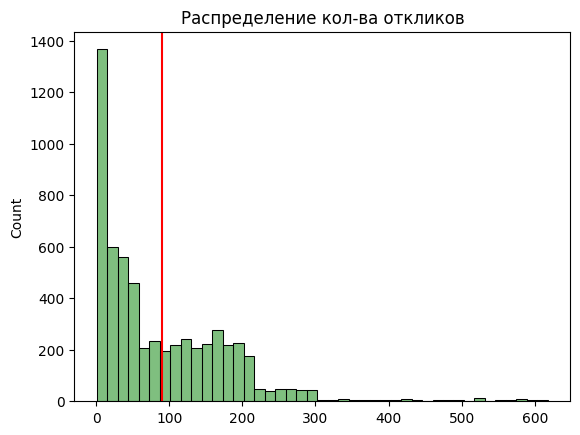

In [ ]:
sns.histplot(cnt_answer, color='green', alpha=.5)
plt.axvline(mean_answer, color = 'red')
plt.title('Распределение кол-ва откликов')
plt.show()

## Пункт 1. Проверяем статкритерий на A/A-тесте

In [ ]:
def aa_testing(signals, n_trial=5_000, alpha=0.05):

    p_vals = []

    # A/A симмуляции
    for _ in range(n_trial):
        hits = np.random.random(len(signals)) < 0.5 # делим на 2 группы
        s_1, s_2 = signals[hits], signals[~hits]
        p_vals.append(ttest_ind(s_1, s_2)[1])
    p_vals = np.array(p_vals)

    fpr = sum(p_vals < alpha) / n_trial
    return p_vals, fpr

In [ ]:
def aa_plotter(pvals, fpr):
  cond = pvals  < 0.05
  plt.axvline(0.05, color='black', linewidth=1.2, label=r'$\alpha$=5%')
  plt.hist([pvals[cond], pvals[~cond]], bins=40, color=['crimson', 'goldenrod'], density=True,
          histtype='barstacked', label=[f'FPR: {round(100*fpr)}%', ''], alpha=0.6)
  plt.title('Результат АА-теста', fontsize=11)
  plt.xlabel('P-value', fontsize=10)
  plt.ylabel('$f(x)$', fontsize=10)
  plt.legend(loc=1, fontsize=10)

Рассчитываем результаты A/A теста

In [ ]:
tt_pvals, tt_fpr = aa_testing(cnt_answer)

Рисуем результаты АА-теста для t-теста

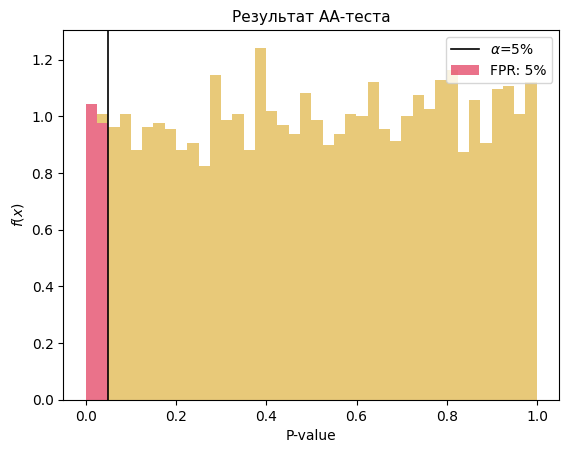

In [ ]:
aa_plotter(tt_pvals, tt_fpr)

## Пункт 2. Считаем размер выборки

Решили, что t-тест подходит для нашего A/B теста.

Давайте теперь разными подходами посчитаем размеры выборок

### 2.1. Через простую формулу

In [ ]:
mde_perc = 0.10

mean_answer_new = mean_answer * (1 + mde_perc)

mde = mean_answer_new - mean_answer

print("Среднее число отзывов на пользователя + размер эффекта: ", round(mean_answer, 3), ' + ', round(mde, 3))
print("Новое значение метрики: ", round(mean_answer_new, 3))

Среднее число отзывов на пользователя + размер эффекта:  89.854  +  8.985
Новое значение метрики:  98.84


In [ ]:
var = np.var(df.cnt_answer)

n = 16 * var / mde**2

print('Необходимое кол-во наблюдений в одну группу: ', int(n))

Необходимое кол-во наблюдений в одну группу:  1671


Мы только что рассчитали необходимое количество наблюдений с помощью формулы (следствия из ЦПТ).

Однако то же самое можно сделать встроенными методами в Python

### 2.2. Через статпакет

В `statsmodels` есть объект `TTestIndPower`, в котором есть метод `solve_power`, который решает общее уравнение для mde, которое мы выводили на лекции

[Вот документация к нему](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.TTestIndPower.solve_power.html#statsmodels.stats.power.TTestIndPower.solve_power)


```python
TTestIndPower.solve_power(
  effect_size=None,  # стандартизированный размер эффекта (т.е. деленный на ско) между двумя средними
  nobs1=None,  # размер первой группы. размер второй определяется как `nobs2 = nobs1 * ratio`
  alpha=None,  # уровень значимости альфа  
  power=None,  # мощность теста
  ratio=1.0,  # отношение наблюдений nobs2 / nobs1
  alternative='two-sided'  # одностороняя или двустороняя гипотеза
)
```



В методе есть 4 аргумента в значении `None`

Если один из них оставить в значении `None`, а в остальные подставить необходимые значения, то метод решит уравнение для оставшегося

Расчитаем пример выше с использованием этого метода

In [ ]:
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()

std = np.std(df.cnt_answer)
effect_size = mde / std   # стандартизированный эффект по определению из документации


nobs1 = analysis.solve_power(
  effect_size=effect_size,
  # nobs1=None,
  alpha=0.05,
  power=0.8,
  ratio=1,
  alternative='two-sided'
)

print('Необходимое кол-во наблюдений в одну группу: ', int(nobs1))

Необходимое кол-во наблюдений в одну группу:  1640


Результат очень похожий на подсчет через формулу: $1671$ и $1640$.

Для пример расчитаем какой MDE мы сможем получить, если в одну из экспериментальных групп наберем $2000$ человек

In [ ]:
n = 2000

effect_size = analysis.solve_power(
  # effect_size=None,
  nobs1=n,
  alpha=0.05,
  power=0.8,
  ratio=1,
  alternative='two-sided'
)

print('Стандартизированный эффект: ', effect_size)
print('Надо домножить на стандартное отклонение, чтобы получить MDE для среднее числа откликов: ', round(effect_size * std, 2))

Стандартизированный эффект:  0.08861483264039895
Надо домножить на стандартное отклонение, чтобы получить MDE для среднее числа откликов:  8.14


### 2.3. Численная оценка необходимого количества наблюдений

Разберем как с помощью бустрапа посчитать MDE для нашего статкритерия.



 1. Устанавливаем в рамках дизайна **уровень значимости $\alpha$**, **увровень ошибки 2-го рода $\beta$** и **желаемый MDE**

 2. Выделяем из датасета по $n$ случайных наблюдений **с повторениями** в две условно экспериментальные группы.

 3. В одной группе каждому значению сигнала прибавим значение MDE.

 4. Рассчитаем, есть ли статистически значимая разница между значениями таргет-метрик этих двух групп на уровне нашей $\alpha$.

 5. Повторим операцию множество раз и посмотрим, в скольких процентах случаев значимой разницы между таргетами нет.

 6. Этот процент должен равняться $\beta$, т.е. ~$20\%$.

 7. Или, наоборот, считаем в скольких процентах случаев была значимая разница и она должна ровнятся мощности $1-\beta$

Создадим функцию, которая считает мощность в зависимости от параметров эксперимента.

In [ ]:
def get_iter_sample_size(signals, n, mde, alpha=0.05):
  pval_list = []

  for _ in range(3000):
    smpl_0 = np.random.choice(signals, size=n, replace=True)
    smpl_1 = np.random.choice(signals, size=n, replace=True)

    smpl_1 = smpl_1 + mde

    p_value = ttest_ind(smpl_0, smpl_1)[1]
    pval_list.append(p_value)

  pval_list = np.array(pval_list)
  power = np.sum(pval_list<alpha) / len(pval_list)

  return power

Начнём с $10$ пользователей.

In [ ]:
res10 = get_iter_sample_size(cnt_answer, 10, mde)

str(round(100 * res10, 2)) + '%'

'5.17%'

Попробуем на $100$.

In [ ]:
res100 = get_iter_sample_size(cnt_answer, 100, mde)

str(round(100 * res100, 2)) + '%'

'10.17%'

Было обнаружено слишком мало прокрасов, а значит, эта выборка тоже слишком мала.

Попробуем на $1000$.

In [ ]:
res1000 = get_iter_sample_size(cnt_answer, 1000, mde)

str(round(100 * res1000, 2)) + '%'

'58.63%'

Всё ещё недостаточно, чтобы разглядеть прокрас размера $MDE$.

In [ ]:
res2500 = get_iter_sample_size(cnt_answer, 2500, mde)

str(round(100 * res2500, 2)) + '%'

'93.67%'

Теперь слишком много)

$2500$ - это чрезмерный размер выборки для данного $MDE$.

Попробуем наш $1671$.

In [ ]:
res1671 = get_iter_sample_size(cnt_answer, 1671, mde)

str(round(100 * res1671, 2)) + '%'

'80.43%'

**Успех !!!** Результат получился в районе $80\%$ мощности

Попробуем подчистить выбросы в наших данных

## Пункт 3. Влияние выбросов

Ограничим выбросы  в датафрейме и посмотрим, как это повлияет на мощность.

In [ ]:
df_clean = df[(df['cnt_answer'] <= 500)]
clean_signals = df_clean.cnt_answer.values

print(len(clean_signals))

5750


In [ ]:
res1671 = get_iter_sample_size(clean_signals, 1671, mde)

str(round(100 * res1671, 2)) + '%'

'88.67%'

**Вывод**

Благодаря удалению выбросов, можем получить при данном дизайне в районе $7$ процентных пунктов прироста мощности без изменения параметров.

# Задача 3. Рост клиентских мотиваций в агрегаторе такси

Вы работаете аналитиком в агрегаторе такси.

Стандартное флоу в нашем агрегаторе - периодически предлагать клиенту скидку в $25\%$ на заказ такси, если этот заказ будет совершен в течение ближайших $12$ часов.

Мы решили протестировать, повлечет ли повышение этой скидки на значительное увеличение конверсии в заказ.

Запустили A/B Тест, в рамках которого в группе В клиенту предлагается скидка в $35\%$ (вместо $25\%$).

Поле `flag_conv` показывает, воспользовался ли клиент этим заказом.\
Рассчитайте, имеет ли повышение акции эффект и сегментируйте свой результат по городам.

**Описание данных:**

 - `user_id` - уникальный идентификатор клиента
 - `flag_group` - экспериментальная группа клиента
 - `id_city` - название города клиента
 - `flag_conv` - флаг создания заказа (1 - заказа, 0 - нет)

In [2]:
df = pd.read_csv('AB_Test_Taxi_clientmotiv.csv')

df.head()

,user_id,flag_group,id_city,flag_conv
0,2001030,pilot,Saint-Petersbourg,1
1,2004390,control,Saint-Petersbourg,0
2,2003763,pilot,Novosibirsk,0
3,2000955,pilot,Rostov,0
4,2002464,pilot,Krasnodar,0


In [3]:
def z_test_2side(s1, s2):
  s1_mean = s1.mean()
  s2_mean = s2.mean()
  s1_std = s1.std()
  s2_std = s2.std()
  n1 = len(s1)
  n2 = len(s2)
  z = (s1_mean - s2_mean) / (s1_std**2 / n1 + s2_std**2 / n2)**.5
  pval = 2 * (1-norm.cdf(abs(z)))
  return s1_mean, s2_mean, s1_mean - s2_mean, z, pval

## Считаем результаты

In [6]:
c_smpl = df[df['flag_group']=='control']['flag_conv'].values
t_smpl = df[df['flag_group']=='pilot']['flag_conv'].values

s1_mean, s2_mean, diff, z, pval = z_test_2side(t_smpl, c_smpl)

print('Конверсия в заказ:')
print(f"\tТест: {round(100.0 * s1_mean,2)}%,  Контроль: {round(100.0*s2_mean,2)}%")
print(f"\tРазница абс: {round(100.0*diff,1)}пп.")
print(f"\tpvalue: {round(pval,3)}, z-статистика: {round(z, 3)}")

Конверсия в заказ:
	Тест: 24.15%,  Контроль: 19.44%
	Разница абс: 4.7пп.
	pvalue: 0.0, z-статистика: 4.169


Получается, что в целом по России наблюдаем статистически значимую разницу между группами А и В.

Теперь необходимо перейти к сегментации, так как у городов есть своя специфика с точки зрения ценообразования, а также с точки зрения поведения водителей и пассажиров.

In [8]:
df_gr = df.groupby(['flag_group','id_city'], as_index=False).agg({
  'flag_conv': 'sum',
  'user_id': 'count'
})

df_gr['conv'] = df_gr['flag_conv'] / df_gr['user_id']

In [9]:
df_gr.sort_values('id_city')

,flag_group,id_city,flag_conv,user_id,conv
0,control,Kazan,65,337,0.192878
7,pilot,Kazan,81,347,0.233429
1,control,Krasnodar,31,138,0.224638
8,pilot,Krasnodar,30,108,0.277778
2,control,Moscow,150,897,0.167224
9,pilot,Moscow,189,861,0.219512
3,control,Novosibirsk,89,427,0.208431
10,pilot,Novosibirsk,96,441,0.217687
4,control,Rostov,24,123,0.195122
11,pilot,Rostov,31,138,0.224638


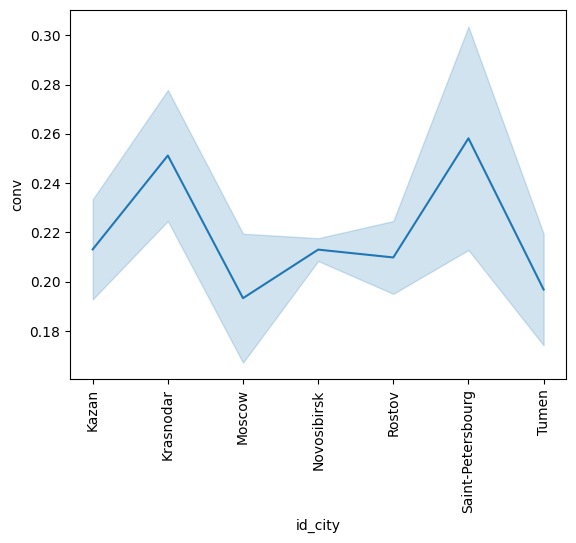

In [10]:
sns.lineplot(df_gr[['id_city','conv']], x="id_city", y="conv")
plt.xticks(rotation=90)
plt.show()

Теперь рассчитаем статистическую значимость различия между группами А и В для каждого города.


In [11]:
for city in df['id_city'].unique():
  print(city)

  c_smpl = df[(df['id_city']==city) & (df['flag_group']=='control')]['flag_conv'].values
  t_smpl = df[(df['id_city']==city) & (df['flag_group']=='pilot')]['flag_conv'].values

  s1_mean, s2_mean, diff, z, pval = z_test_2side(t_smpl, c_smpl)

  print(f"\tТест: {round(100.0 * s1_mean,2)}%,  Контроль: {round(100.0*s2_mean,2)}%")
  print(f"\tРазница абс: {round(100.0*diff,1)}пп.")
  print(f"\tpvalue: {round(pval,3)}, z-статистика: {round(z, 3)}")

Saint-Petersbourg
	Тест: 30.35%,  Контроль: 21.29%
	Разница абс: 9.1пп.
	pvalue: 0.0, z-статистика: 3.689
Novosibirsk
	Тест: 21.77%,  Контроль: 20.84%
	Разница абс: 0.9пп.
	pvalue: 0.739, z-статистика: 0.333
Rostov
	Тест: 22.46%,  Контроль: 19.51%
	Разница абс: 3.0пп.
	pvalue: 0.558, z-статистика: 0.586
Krasnodar
	Тест: 27.78%,  Контроль: 22.46%
	Разница абс: 5.3пп.
	pvalue: 0.341, z-статистика: 0.951
Kazan
	Тест: 23.34%,  Контроль: 19.29%
	Разница абс: 4.1пп.
	pvalue: 0.195, z-статистика: 1.297
Tumen
	Тест: 17.42%,  Контроль: 21.95%
	Разница абс: -4.5пп.
	pvalue: 0.364, z-статистика: -0.909
Moscow
	Тест: 21.95%,  Контроль: 16.72%
	Разница абс: 5.2пп.
	pvalue: 0.005, z-статистика: 2.778


Только два города показали статистически значимые различия:
 - В Москве +5.2 п.п.
 - В Санкт-Петербурге +9.1 п.п.

Причиной того, что прокрасились именно эти два города, может быть то, что цены в МСК и СПБ выше, а значит, и 10% изменение цены представляет собой большее количество рублей.

## Считаем финансовую выгоду

Скидка подразумевает то, что мы недополучаем деньги за заказы.

Может оказаться, что скидка слишком большая и что нам невыгодно предоставлять такую скидку несмотря на рост конверсии.

In [12]:
df_msk = df[df['id_city']=='Moscow']
df_spb = df[df['id_city']=='Saint-Petersbourg']

### Запишем тестовую и контрольную конверсии МСК в переменные
o2r_msk_ctrl = df_msk[df_msk['flag_group']=='control']['flag_conv'].mean()
o2r_msk_test = df_msk[df_msk['flag_group']=='pilot']['flag_conv'].mean()

### Запишем тестовую и контрольную конверсии СПБ в переменные
o2r_spb_ctrl = df_spb[df_spb['flag_group']=='control']['flag_conv'].mean()
o2r_spb_test = df_spb[df_spb['flag_group']=='pilot']['flag_conv'].mean()

In [13]:
### Кол-во заходов в неделю в МСК и СПБ запишем в переменные
n_all_msk = len(df_msk)
n_all_spb = len(df_spb)

print("В МСК в неделю ", n_all_msk)
print("В СПБ в неделю ", n_all_spb)

В МСК в неделю  1758
В СПБ в неделю  1256


In [14]:
### Кол-во заходов в день в МСК и СПБ запишем в переменные
n_day_msk = n_all_msk // 7
n_day_spb = n_all_spb // 7

print("В МСК в день ", n_day_msk)
print("В СПБ в день ", n_day_spb)

В МСК в день  251
В СПБ в день  179


In [15]:
### Кол-во поездок (заказов) в день в МСК и СПБ запишем в переменные (если бы 100% были тестом или 100% контролем)
n_trip_day_msk_ctrl = round(n_day_msk * o2r_msk_ctrl)
n_trip_day_spb_ctrl = round(n_day_spb * o2r_spb_ctrl)

n_trip_day_msk_test = round(n_day_msk * o2r_msk_test)
n_trip_day_spb_test = round(n_day_spb * o2r_spb_test)

print("В Москве")
print("Контроль: ", n_trip_day_msk_ctrl)
print("Тест: ", n_trip_day_msk_test)

print()

print("В Санкт-Петербурге")
print("Контроль: ", n_trip_day_spb_ctrl)
print("Тест: ", n_trip_day_spb_test)

В Москве
Контроль:  42
Тест:  55

В Санкт-Петербурге
Контроль:  38
Тест:  54


In [16]:
#### Рассчитаем цены со скидками А и В
avg_price = 700
avg_price_25 = 700 * .75
avg_price_35 = 700 * .65

print(avg_price_25)
print(avg_price_35)

525.0
455.0


In [17]:
print("В Москве")
print("100% контроль: ", n_trip_day_msk_ctrl * avg_price_25)
print("50% контроль, 50% тест: ", n_trip_day_msk_ctrl / 2 * avg_price_25 + n_trip_day_msk_test / 2 * avg_price_35)
print("100% тест: ", n_trip_day_msk_test * avg_price_35)

print()

print("В Санкт-Петербурге")
print("100% контроль: ", n_trip_day_spb_ctrl * avg_price_25)
print("50% контроль, 50% тест: ", n_trip_day_spb_ctrl / 2 * avg_price_25 + n_trip_day_spb_test / 2 * avg_price_35)
print("100% тест: ", n_trip_day_spb_test * avg_price_35)

В Москве
100% контроль:  22050.0
50% контроль, 50% тест:  23537.5
100% тест:  25025.0

В Санкт-Петербурге
100% контроль:  19950.0
50% контроль, 50% тест:  22260.0
100% тест:  24570.0


**Вывод:** В обоих городах выгодно раскатить воздействие В.


А теперь представим абстрактную ситуацию, в которой мы принимаем результаты АБ теста в Новосибирске, несмотря на отсутствие статистической значимости эксперимента.

**Выгодна ли акция в Новосибирске?**

In [18]:
df_nov = df[df['id_city']=='Novosibirsk']

o2r_nov_ctrl = df_nov[df_nov['flag_group']=='control']['flag_conv'].mean()
o2r_nov_test = df_nov[df_nov['flag_group']=='pilot']['flag_conv'].mean()

n_nov_week = len(df_nov)
n_nov_day = n_nov_week // 7

n_nov_trip_day_ctrl = round(n_nov_day * o2r_nov_ctrl)
n_nov_trip_day_test = round(n_nov_day * o2r_nov_test)

print(n_nov_trip_day_ctrl)
print(n_nov_trip_day_test)

26
27


In [19]:
print("100% контроль: ", n_nov_trip_day_ctrl * avg_price_25)
print("50% контроль, 50% тест: ", n_nov_trip_day_ctrl / 2 * avg_price_25 + n_nov_trip_day_test / 2 * avg_price_35)
print("100% тест: ", n_nov_trip_day_test * avg_price_35)

100% контроль:  13650.0
50% контроль, 50% тест:  12967.5
100% тест:  12285.0


Видим, что в Новосибирске подобная акция была бы *финансово невыгодна*.

<br>

Начиная с какого момента становится выгодно?

$$525х < 455y$$
$$x < (455 / 525)y$$
$$y > (525 / 455)x$$

In [20]:
print(round(525 / 455 - 1, 2))
print(round(0.75 / .65 - 1, 2))

0.15
0.15


Т.е. число заказов с новой скидкой должно вырасти на $15\%$.

Исходя из данного правила, определим те города, для которых акция была бы выгодна.

In [21]:
df_gr_by_city = df.groupby('id_city').agg(avg = ('flag_conv','mean'), cnt_order_week = ('user_id', 'count')).reset_index()
df_gr_by_city['cnt_order_day'] = df_gr_by_city['cnt_order_week'] // 7

df_gr_by_city

,id_city,avg,cnt_order_week,cnt_order_day
0,Kazan,0.213450,684,97
1,Krasnodar,0.247967,246,35
2,Moscow,0.192833,1758,251
3,Novosibirsk,0.213134,868,124
4,Rostov,0.210728,261,37
5,Saint-Petersbourg,0.258758,1256,179
6,Tumen,0.196078,255,36


Увеличим количество поездок на $15\%$.

In [22]:
df_gr_by_city['trips_by_day'] = round(df_gr_by_city['cnt_order_day'] * df_gr_by_city['avg'])
df_gr_by_city['trips_by_day_plus15'] = round(df_gr_by_city['trips_by_day'] * 1.15)

df_gr_by_city

,id_city,avg,cnt_order_week,cnt_order_day,trips_by_day,trips_by_day_plus15
0,Kazan,0.213450,684,97,21.0,24.0
1,Krasnodar,0.247967,246,35,9.0,10.0
2,Moscow,0.192833,1758,251,48.0,55.0
3,Novosibirsk,0.213134,868,124,26.0,30.0
4,Rostov,0.210728,261,37,8.0,9.0
5,Saint-Petersbourg,0.258758,1256,179,46.0,53.0
6,Tumen,0.196078,255,36,7.0,8.0


Рассчитаем теперь, на сколько должна увеличиться конверсия, чтобы количество поездок выросло на $15\%$.

In [23]:
df_gr_by_city['avg_to_be'] = df_gr_by_city['trips_by_day_plus15'] / df_gr_by_city['cnt_order_day']
df_gr_by_city['mde'] = df_gr_by_city['avg_to_be'] - df_gr_by_city['avg'] + .01

df_gr_by_city

,id_city,avg,cnt_order_week,cnt_order_day,trips_by_day,trips_by_day_plus15,avg_to_be,mde
0,Kazan,0.213450,684,97,21.0,24.0,0.247423,0.043972
1,Krasnodar,0.247967,246,35,9.0,10.0,0.285714,0.047747
2,Moscow,0.192833,1758,251,48.0,55.0,0.219124,0.036291
3,Novosibirsk,0.213134,868,124,26.0,30.0,0.241935,0.038802
4,Rostov,0.210728,261,37,8.0,9.0,0.243243,0.042515
5,Saint-Petersbourg,0.258758,1256,179,46.0,53.0,0.296089,0.047331
6,Tumen,0.196078,255,36,7.0,8.0,0.222222,0.036144


Теперь рассчитаем для каждого города необходимое количество наблюдений для того, чтобы достичь того самого граничного $MDE$.

In [24]:
df_gr_by_city['n'] = 16 * df_gr_by_city['avg'] * (1 - df_gr_by_city['avg']) / (df_gr_by_city['mde']**2)

df_gr_by_city

,id_city,avg,cnt_order_week,cnt_order_day,trips_by_day,trips_by_day_plus15,avg_to_be,mde,n
0,Kazan,0.213450,684,97,21.0,24.0,0.247423,0.043972,1389.257684
1,Krasnodar,0.247967,246,35,9.0,10.0,0.285714,0.047747,1308.768041
2,Moscow,0.192833,1758,251,48.0,55.0,0.219124,0.036291,1890.917807
3,Novosibirsk,0.213134,868,124,26.0,30.0,0.241935,0.038802,1782.248464
4,Rostov,0.210728,261,37,8.0,9.0,0.243243,0.042515,1472.241024
5,Saint-Petersbourg,0.258758,1256,179,46.0,53.0,0.296089,0.047331,1369.855034
6,Tumen,0.196078,255,36,7.0,8.0,0.222222,0.036144,1930.616823


Перейдём к днлительности теста (количеству дней)

In [25]:
df_gr_by_city['days_needed'] = round(df_gr_by_city['n'] * 2 / df_gr_by_city['cnt_order_day'])

df_gr_by_city

,id_city,avg,cnt_order_week,cnt_order_day,trips_by_day,trips_by_day_plus15,avg_to_be,mde,n,days_needed
0,Kazan,0.213450,684,97,21.0,24.0,0.247423,0.043972,1389.257684,29.0
1,Krasnodar,0.247967,246,35,9.0,10.0,0.285714,0.047747,1308.768041,75.0
2,Moscow,0.192833,1758,251,48.0,55.0,0.219124,0.036291,1890.917807,15.0
3,Novosibirsk,0.213134,868,124,26.0,30.0,0.241935,0.038802,1782.248464,29.0
4,Rostov,0.210728,261,37,8.0,9.0,0.243243,0.042515,1472.241024,80.0
5,Saint-Petersbourg,0.258758,1256,179,46.0,53.0,0.296089,0.047331,1369.855034,15.0
6,Tumen,0.196078,255,36,7.0,8.0,0.222222,0.036144,1930.616823,107.0


# Дополнительная задача. Две нормально распределённые случайные величины

Имеются два независимых наблюдения $X\sim N(a,1)$ и $Y\sim N(b,1)$.

Построй критерии для проверки гипотезы $H_0:a=b$ против разных альтернатив.

**Решение**

Так как $X$ и $Y$ независимы, то

$$
X-Y\sim N(a-b,2).
$$

При гипотезе $H_0:a=b$ имеем

$$
X-Y\sim N(0,2).
$$

Поэтому центральная статистика:

$$
T=\frac{X-Y}{\sqrt2}\sim N(0,1)
$$

при верности $H_0$.

Пусть уровень значимости равен $\alpha$, а $u_p$ — квантиль уровня $p$ стандартного нормального распределения.

Для альтернативы $H_1:a>b$ отвергаем $H_0$, если

$$
T>u_{1-\alpha}.
$$

Для альтернативы $H_1:a<b$ отвергаем $H_0$, если

$$
T<u_{\alpha}.
$$

Для двусторонней альтернативы $H_1:a\neq b$ отвергаем $H_0$, если

$$
|T|>u_{1-\alpha/2}.
$$

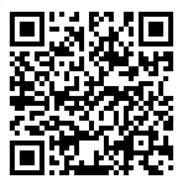